# Random Forest vs Logistic Regression: Margin Analysis

Compare prediction confidence patterns between Random Forest and Logistic Regression models.

**Analysis:**
- Margin = score(top-1) - score(top-2)
- Accuracy vs margin threshold
- Coverage vs margin threshold
- Features: DTW + Optimal Transport + Centroid

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
import warnings
warnings.filterwarnings('ignore')
import os

%matplotlib inline

from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR,
    CENTROID_NORM_DIVISOR,
    NUM_CONTOUR_POINTS
)

import cell_matching_utils as recon_module

# Adaptive OT regularization
def solve_ot_with_adaptive_reg(C, weights_a, weights_b):
    adaptive_reg = max(np.max(C) / 10.0, 50000.0)
    original_reg = recon_module.SINKHORN_REG
    recon_module.SINKHORN_REG = adaptive_reg
    try:
        result = recon_module.solve_optimal_transport(C, weights_a, weights_b, use_gpu=True)
        return result
    finally:
        recon_module.SINKHORN_REG = original_reg

# Plotting setup
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.linewidth': 0.5,
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'pdf.fonttype': 42
})

COLORS = {
    'rf': '#2E86AB',
    'linear': '#F18F01',
    'correct': '#06A77D',
    'incorrect': '#D62246'
}

WINDOW_SIZE = 200

In [13]:
# Utility Functions

def uniform_resample_contour(contour, target_num_points):
    if len(contour) == target_num_points:
        return contour
    
    if not np.allclose(contour[0], contour[-1]):
        contour = np.vstack([contour, contour[0:1]])
    
    dists = np.sqrt(np.sum(np.diff(contour, axis=0)**2, axis=1))
    cumulative_dists = np.concatenate([[0], np.cumsum(dists)])
    total_length = cumulative_dists[-1]
    
    if total_length == 0:
        return np.tile(contour[0], (target_num_points, 1))
    
    target_dists = np.linspace(0, total_length, target_num_points)
    resampled_x = np.interp(target_dists, cumulative_dists, contour[:, 0])
    resampled_y = np.interp(target_dists, cumulative_dists, contour[:, 1])
    
    return np.column_stack([resampled_x, resampled_y])

def get_candidates_in_window(anchor, candidates, window_size=100):
    cx, cy = anchor.centroid
    window_half = window_size / 2.0
    
    valid_candidates = []
    for candidate in candidates:
        cx2, cy2 = candidate.centroid
        if abs(cx2 - cx) <= window_half and abs(cy2 - cy) <= window_half:
            valid_candidates.append(candidate)
    
    return valid_candidates

In [14]:
# Feature Calculation

def calculate_features(cell1, cell2, cells_by_slice):
    features = {}
    
    # DTW
    if hasattr(cell1, 'contour_points_200') and hasattr(cell2, 'contour_points_200'):
        dtw_raw = dtw_distance_gpu_single(cell1.contour_points_200, cell2.contour_points_200)
    else:
        contour1 = uniform_resample_contour(cell1.contour_points, NUM_CONTOUR_POINTS)
        contour2 = uniform_resample_contour(cell2.contour_points, NUM_CONTOUR_POINTS)
        dtw_raw = dtw_distance_gpu_single(contour1, contour2)
    features['dtw_loss'] = min(10.0, dtw_raw / DTW_NORM_DIVISOR * 10.0)
    
    # OT
    cluster1 = get_cluster_cells(cell1, cells_by_slice)
    cluster2 = get_cluster_cells(cell2, cells_by_slice)
    if len(cluster1) > 1 and len(cluster2) > 1:
        C = compute_ot_cost_matrix(cluster1, cluster2)
        areas1 = np.array([c.area for c in cluster1])
        areas2 = np.array([c.area for c in cluster2])
        weights1 = areas1 / areas1.sum()
        weights2 = areas2 / areas2.sum()
        ot_raw, _ = solve_ot_with_adaptive_reg(C, weights1, weights2)
        features['ot_loss'] = min(10.0, ot_raw / OT_NORM_DIVISOR * 10.0)
    else:
        features['ot_loss'] = 0.0
    
    # Centroid
    cx1, cy1 = cell1.centroid
    cx2, cy2 = cell2.centroid
    centroid_dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
    features['centroid_loss'] = min(10.0, centroid_dist / CENTROID_NORM_DIVISOR * 10.0)
    
    return features


In [15]:
#  Dataset Construction

def build_dataset(golden_df, cells_by_slice):
    samples = []
    
    for idx, row in golden_df.iterrows():
        start_layer = row['Start_layer']
        end_layer = row['End_layer']
        start_cell_id = row['Start_cell']
        true_match_id = row['End_cell']
        num_annotators = row['number']
        
        if end_layer - start_layer != 1:
            continue
        
        anchor = None
        for c in cells_by_slice.get(start_layer, []):
            if c.cell_id == start_cell_id:
                anchor = c
                break
        
        if anchor is None:
            continue
        
        anchor_id = f"L{start_layer}_{start_cell_id}"
        candidates = cells_by_slice.get(end_layer, [])
        candidates_in_window = get_candidates_in_window(anchor, candidates, WINDOW_SIZE)
        
        if len(candidates_in_window) == 0:
            continue
        
        for candidate in candidates_in_window:
            features = calculate_features(anchor, candidate, cells_by_slice)
            is_true_match = (candidate.cell_id == true_match_id)
            
            sample = {
                'anchor_id': anchor_id,
                'start_layer': start_layer,
                'end_layer': end_layer,
                'start_cell_id': start_cell_id,
                'candidate_cell_id': candidate.cell_id,
                'true_match_id': true_match_id,
                'is_true_match': is_true_match,
                'num_annotators': num_annotators,
                'num_candidates': len(candidates_in_window)
            }
            sample.update(features)
            samples.append(sample)
    
    df = pd.DataFrame(samples)
    return df


In [16]:
# Model Training

def train_and_evaluate_model(df, model_type='rf'):
    feature_names = ['dtw_loss', 'ot_loss', 'centroid_loss']
    
    X = df[feature_names].values
    y = df['is_true_match'].astype(int).values
    anchor_ids = df['anchor_id'].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    if model_type == 'rf':
        model = RandomForestClassifier(
            n_estimators=100, 
            max_depth=10, 
            random_state=42,
            class_weight='balanced', 
            n_jobs=-1
        )
    else:
        model = LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight='balanced',
            solver='lbfgs'
        )
    
    gkf = GroupKFold(n_splits=5)
    y_pred_scores = np.zeros(len(y))
    
    for train_idx, val_idx in gkf.split(X_scaled, y, groups=anchor_ids):
        X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
        y_train = y[train_idx]
        model.fit(X_train, y_train)
        y_pred_scores[val_idx] = model.predict_proba(X_val)[:, 1]
    
    df_with_scores = df.copy()
    df_with_scores['pred_score'] = y_pred_scores
    
    return df_with_scores


In [17]:
# Margin Analysis

def calculate_margin_and_accuracy(df_with_scores):
    results = []
    unique_anchors = df_with_scores['anchor_id'].unique()
    
    for anchor_id in unique_anchors:
        anchor_df = df_with_scores[df_with_scores['anchor_id'] == anchor_id].copy()
        anchor_df_sorted = anchor_df.sort_values('pred_score', ascending=False)
        
        top1 = anchor_df_sorted.iloc[0]
        top1_score = top1['pred_score']
        
        if len(anchor_df_sorted) > 1:
            top2_score = anchor_df_sorted.iloc[1]['pred_score']
            margin = top1_score - top2_score
        else:
            top2_score = 0.0
            margin = top1_score
        
        true_match_df = anchor_df[anchor_df['is_true_match'] == 1]
        if len(true_match_df) == 0:
            continue
        
        true_match = true_match_df.iloc[0]
        is_correct = (top1['candidate_cell_id'] == true_match['candidate_cell_id'])
        
        results.append({
            'anchor_id': anchor_id,
            'is_correct': is_correct,
            'top1_score': top1_score,
            'top2_score': top2_score,
            'margin': margin,
            'num_candidates': top1['num_candidates'],
            'num_annotators': top1['num_annotators'],
            'true_match_rank': (anchor_df['pred_score'] > true_match['pred_score']).sum() + 1
        })
    
    return pd.DataFrame(results)

def analyze_margin_thresholds(results_df, model_name):
    margin_thresholds = [0.0, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
    
    margin_stats = []
    for threshold in margin_thresholds:
        filtered = results_df[results_df['margin'] >= threshold]
        
        if len(filtered) == 0:
            continue
        
        n_samples = len(filtered)
        n_correct = filtered['is_correct'].sum()
        accuracy = n_correct / n_samples
        coverage = n_samples / len(results_df) * 100
        
        margin_stats.append({
            'model': model_name,
            'threshold': threshold,
            'num_samples': n_samples,
            'num_correct': n_correct,
            'accuracy': accuracy,
            'coverage': coverage
        })
    
    return pd.DataFrame(margin_stats)


In [18]:
# Comparison Functions

def compare_models(rf_results, linear_results, rf_stats, linear_stats):
    rf_acc = rf_results['is_correct'].mean()
    linear_acc = linear_results['is_correct'].mean()
    
    print("\nOverall Accuracy:")
    print(f"  Random Forest:       {rf_acc:.4f}")
    print(f"  Logistic Regression: {linear_acc:.4f}")
    print(f"  Difference:          {(rf_acc - linear_acc):+.4f}")
    
    print("\nMargin Statistics:")
    print(f"  {'Model':<20s} {'Mean':<12s} {'Median':<12s}")
    print(f"  {'-'*45}")
    print(f"  {'Random Forest':<20s} {rf_results['margin'].mean():<12.4f} {rf_results['margin'].median():<12.4f}")
    print(f"  {'Logistic Regression':<20s} {linear_results['margin'].mean():<12.4f} {linear_results['margin'].median():<12.4f}")


In [19]:
# Visualization

def plot_linear_accuracy_coverage_tradeoff(linear_stats, output_dir):
    fig, ax1 = plt.subplots(figsize=(4.5, 3.5))
    
    color_acc = COLORS['correct']
    ax1.set_xlabel('Margin Threshold', fontsize=9)
    ax1.set_ylabel('Accuracy', fontsize=9, color=color_acc)
    line1 = ax1.plot(linear_stats['threshold'], linear_stats['accuracy'], 
                     'o-', color=color_acc, linewidth=2, markersize=6,
                     label='Accuracy')
    ax1.tick_params(axis='y', labelcolor=color_acc)
    ax1.set_ylim([0.5, 1.02])
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.spines['top'].set_visible(False)
    
    ax2 = ax1.twinx()
    color_cov = COLORS['linear']
    ax2.set_ylabel('Coverage (%)', fontsize=9, color=color_cov)
    line2 = ax2.plot(linear_stats['threshold'], linear_stats['coverage'],
                     's-', color=color_cov, linewidth=2, markersize=6,
                     label='Coverage')
    ax2.tick_params(axis='y', labelcolor=color_cov)
    ax2.set_ylim([0, 105])
    ax2.spines['top'].set_visible(False)
    
    ax1.set_title('Logistic Regression: Accuracy-Coverage Trade-off', 
                 fontsize=10, pad=10)
    
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center left', fontsize=8)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/linear_accuracy_coverage_tradeoff.pdf', bbox_inches='tight')
    plt.show()

def plot_margin_vs_correctness(rf_results, linear_results, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    
    # Random Forest
    ax = axes[0]
    rf_correct_mask = rf_results['is_correct']
    
    jitter = 0.05
    np.random.seed(42)
    y_correct = np.random.randn(rf_correct_mask.sum()) * jitter + 1
    y_incorrect = np.random.randn((~rf_correct_mask).sum()) * jitter
    
    ax.scatter(rf_results[rf_correct_mask]['margin'], y_correct,
              s=20, alpha=0.4, color=COLORS['correct'], label='Correct')
    ax.scatter(rf_results[~rf_correct_mask]['margin'], y_incorrect,
              s=20, alpha=0.4, color=COLORS['incorrect'], label='Incorrect')
    
    ax.set_xlabel('Margin', fontsize=9)
    ax.set_ylabel('Prediction Result', fontsize=9)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Incorrect', 'Correct'])
    ax.set_title('A. Random Forest', fontsize=10, loc='left')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, axis='x')
    ax.set_ylim([-0.3, 1.3])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Logistic Regression
    ax = axes[1]
    linear_correct_mask = linear_results['is_correct']
    
    y_correct = np.random.randn(linear_correct_mask.sum()) * jitter + 1
    y_incorrect = np.random.randn((~linear_correct_mask).sum()) * jitter
    
    ax.scatter(linear_results[linear_correct_mask]['margin'], y_correct,
              s=20, alpha=0.4, color=COLORS['correct'], label='Correct')
    ax.scatter(linear_results[~linear_correct_mask]['margin'], y_incorrect,
              s=20, alpha=0.4, color=COLORS['incorrect'], label='Incorrect')
    
    ax.set_xlabel('Margin', fontsize=9)
    ax.set_ylabel('Prediction Result', fontsize=9)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Incorrect', 'Correct'])
    ax.set_title('B. Logistic Regression', fontsize=10, loc='left')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, axis='x')
    ax.set_ylim([-0.3, 1.3])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/margin_vs_correctness.pdf', bbox_inches='tight')
    plt.show()


In [20]:
#  Load Data
golden_df = pd.read_csv('High_confidence_pairing_4nums_fullnames.csv')
cells_by_slice = load_cells_from_csv_files('cell-002_processed')

output_dir = 'rf_vs_linear_margin_comparison'
os.makedirs(output_dir, exist_ok=True)

print(f"Loaded {len(golden_df)} golden pairings")
print(f"Loaded {sum(len(cells) for cells in cells_by_slice.values())} cells")

Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:16<00:00,  5.09s/it]


Total cells loaded: 12009
Loaded 340 golden pairings
Loaded 12009 cells


In [21]:
# Build Dataset
df = build_dataset(golden_df, cells_by_slice)
df.to_csv(f'{output_dir}/dataset.csv', index=False)

print(f"\nDataset: {len(df)} samples from {df['anchor_id'].nunique()} anchors")
print(f"  Positive: {(df['is_true_match'] == 1).sum()}")
print(f"  Negative: {(df['is_true_match'] == 0).sum()}")


Dataset: 6815 samples from 338 anchors
  Positive: 331
  Negative: 6484


In [22]:
# Train Random Forest
print("\nTraining Random Forest...")
df_rf = train_and_evaluate_model(df, model_type='rf')
rf_results = calculate_margin_and_accuracy(df_rf)
rf_stats = analyze_margin_thresholds(rf_results, 'Random Forest')

rf_results.to_csv(f'{output_dir}/rf_results.csv', index=False)
rf_stats.to_csv(f'{output_dir}/rf_margin_stats.csv', index=False)

print(f"  Accuracy: {rf_results['is_correct'].mean():.4f}")
print(f"  Mean Margin: {rf_results['margin'].mean():.4f}")


Training Random Forest...
  Accuracy: 0.8338
  Mean Margin: 0.4984


In [23]:
# Train Logistic Regression
print("\nTraining Logistic Regression...")
df_linear = train_and_evaluate_model(df, model_type='linear')
linear_results = calculate_margin_and_accuracy(df_linear)
linear_stats = analyze_margin_thresholds(linear_results, 'Logistic Regression')

linear_results.to_csv(f'{output_dir}/linear_results.csv', index=False)
linear_stats.to_csv(f'{output_dir}/linear_margin_stats.csv', index=False)

print(f"  Accuracy: {linear_results['is_correct'].mean():.4f}")
print(f"  Mean Margin: {linear_results['margin'].mean():.4f}")


Training Logistic Regression...
  Accuracy: 0.8550
  Mean Margin: 0.3128


In [24]:
compare_models(rf_results, linear_results, rf_stats, linear_stats)
combined_stats = pd.concat([rf_stats, linear_stats], ignore_index=True)
combined_stats.to_csv(f'{output_dir}/combined_margin_stats.csv', index=False)


Overall Accuracy:
  Random Forest:       0.8338
  Logistic Regression: 0.8550
  Difference:          -0.0211

Margin Statistics:
  Model                Mean         Median      
  ---------------------------------------------
  Random Forest        0.4984       0.5651      
  Logistic Regression  0.3128       0.2361      


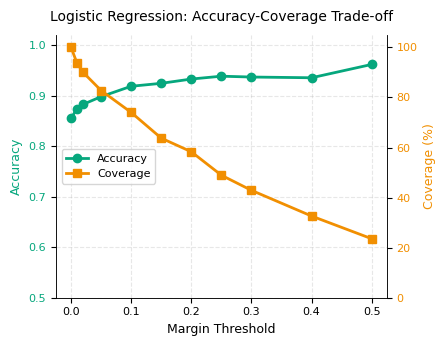

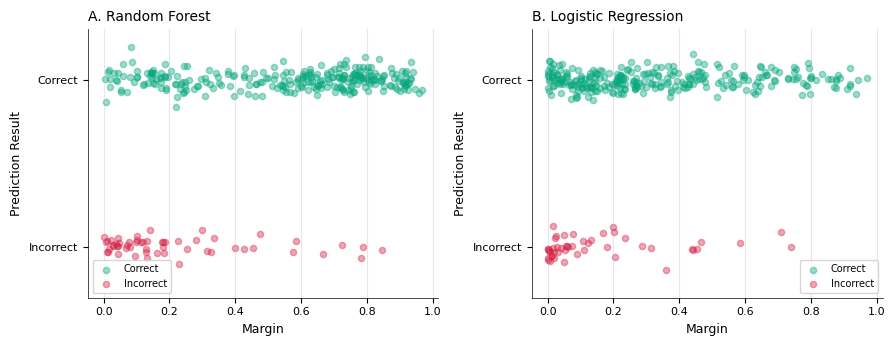

In [25]:
plot_linear_accuracy_coverage_tradeoff(linear_stats, output_dir)
plot_margin_vs_correctness(rf_results, linear_results, output_dir)

In [26]:
rf_acc = rf_results['is_correct'].mean()
linear_acc = linear_results['is_correct'].mean()

rf_best = rf_stats.loc[rf_stats['accuracy'].idxmax()]
linear_best = linear_stats.loc[linear_stats['accuracy'].idxmax()]

print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f"\nPerformance:")
print(f"  RF:     {rf_acc:.4f}")
print(f"  Linear: {linear_acc:.4f}")
print(f"  Gap:    {abs(rf_acc - linear_acc):.4f}")

print(f"\nOptimal Thresholds:")
print(f"  RF:     ≥{rf_best['threshold']:.2f} (Acc={rf_best['accuracy']:.4f}, Cov={rf_best['coverage']:.1f}%)")
print(f"  Linear: ≥{linear_best['threshold']:.2f} (Acc={linear_best['accuracy']:.4f}, Cov={linear_best['coverage']:.1f}%)")

print(f"\nFigures:")
print(f"  - linear_accuracy_coverage_tradeoff.pdf")
print(f"  - margin_vs_correctness.pdf")


SUMMARY

Performance:
  RF:     0.8338
  Linear: 0.8550
  Gap:    0.0211

Optimal Thresholds:
  RF:     ≥0.50 (Acc=0.9615, Cov=55.0%)
  Linear: ≥0.50 (Acc=0.9615, Cov=23.6%)

Figures:
  - linear_accuracy_coverage_tradeoff.pdf
  - margin_vs_correctness.pdf
